In [1]:
import numpy as np
import matplotlib.pyplot as plt
import flups
from glob import glob
from collections import namedtuple
from scipy.signal import savgol_filter
import lmfit
from itertools import chain
from scipy.interpolate import UnivariateSpline

In [2]:
%matplotlib widget

In [3]:
def between(x, l, u):
    return (x>l) & (x<u)

# Load and View measured dye spectra

In [4]:
# load photometric measurements
pcfs = glob("260605_FLUPS_pcf_*.txt")
pcfs = {fn: np.loadtxt(fn).T for fn in pcfs}

pix = np.arange(len(list(pcfs.values())[0][0]))
wl = pix*0.171025+249.95 # wavelength calibration
wl_exp = wl.copy()

In [5]:
print(pcfs.keys())


dict_keys(['260605_FLUPS_pcf_C153.txt', '260605_FLUPS_pcf_C6H.txt', '260605_FLUPS_pcf_PBBO.txt'])


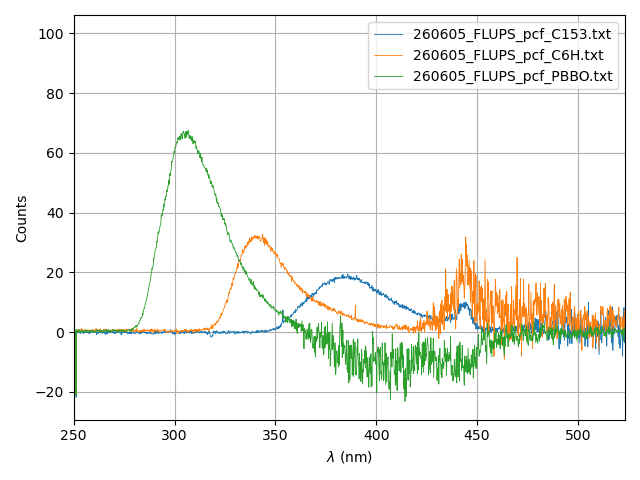

In [6]:
plt.figure()
for fn, data in pcfs.items():
    pix, s = data  # data hat zwei Zeilen: erste = pix, zweite = s
    plt.plot(wl, s, lw=0.6, label=fn)
plt.xlim(wl[0], wl[-1])
plt.legend()
plt.xlabel("$\lambda$ (nm)")
plt.ylabel("Counts")
plt.grid()
plt.tight_layout()
plt.show()


In [297]:
# choose masks for dyes 

masks = {}  

masks["260605_FLUPS_pcf_PBBO.txt"] = between(wl, 275, 345) 
masks["260605_FLUPS_pcf_C6H.txt"] = between(wl, 320, 400) 
masks["260605_FLUPS_pcf_C153.txt"] = between(wl, 360, 420) 
#masks["250825_FLUPS_pcf_R6G.txt"] = between(wl, 375, 425)
#masks["250825_FLUPS_pcf_C153.txt"] = between(wl, 337, np.infty)
#masks["250825_FLUPS_pcf_DCM.txt"] = between(wl, 350, np.infty)


# Compute photometric correction function

## Laod reference spectra

In [298]:
import pandas as pd
import numpy as np

# defines names of dyes and files
dateien = {
    "PBBO": "PBBO_ref_dye.csv",
    "C6H": "C6H_ref_dye.csv",
    "C153": "C153_ref_dye.csv",
}

# Alles einlesen
spektren = {}
for name, fname in dateien.items():
    df = pd.read_csv(fname, sep=";", decimal=".")  # anpassen falls nötig
    spektren[name] = df.to_numpy()


## Prepare measurement and reference data

In [299]:
# unpack data do "downconversion" and repack data 

ref_record = namedtuple("ref_record", ("wl_f", "wl_u", "s_f", "s_u"))

wl_f = 1/(1/wl_exp - 1/1340)  # "downconverted wavelength" gate wavelwngth = 1340 nm
references = {}

for k, d in spektren.items():
    if k == "":  # exclude this measurement
        continue
    dye = k           
    wl_org = d[:,0]
    s = d[:,1]

    s = np.interp(wl_f, wl_org, s) # interpolate spectra from original (exp) spectrum to "downconverted" spectrum 
    s /= np.max(s) # normalization

    jac = wl_f**2/ wl_exp**2 # apply Jacobian for unit transformation
    s_u = s*jac
    s_u /= np.max(s_u) # normalization

    references[k] = ref_record(wl_f, wl_exp, s, s_u)
    #references[dye] = ref_record(wl_f, wl_exp, s, s_u)  

In [300]:
print(dye)

C153


In [301]:
# asign masks to measured dye spectra and smoothen and normalize them 

meas = {}
meas_record = namedtuple("meas_record", ("wl_u", "s_u", "is_valid"))
for fn, data in pcfs.items():
    dye = fn.split("_pcf_")[1].split("_")[0].split(".")[0]
    m = masks.get(fn, np.full_like(wl, True))
    filt = savgol_filter(data, 11, 2)
    meas[dye] = meas_record(wl_exp, filt/np.max(filt), m)

In [302]:
meas = {}
meas_record = namedtuple("meas_record", ("wl_u", "s_u", "is_valid"))

for fn, data in pcfs.items():
    dye = fn.split("_pcf_")[1].split("_")[0].split(".")[0]
    s = data[1]                                
    m = masks.get(fn, np.ones_like(s, bool))   
    filt = savgol_filter(s, 11, 2)
    meas[dye] = meas_record(wl_exp, s/np.max(filt), m)

In [303]:
print(meas.keys())

dict_keys(['C153', 'C6H', 'PBBO'])


## Calculate the correction factor

$$
c = S_\mathrm{ref}(\lambda_\mathrm{U})/S_\mathrm{FLUPS}(\lambda_\mathrm{U})
$$

In [304]:
pcf_curves = {}
for k, r in references.items():
    ref_wl = references[k].wl_u
    ref_s = references[k].s_u
    c = np.interp(meas[k].wl_u, ref_wl, ref_s)/meas[k].s_u # insterpolate reference onto measurement axis and then divide
    c = np.where(meas[k].is_valid, c, np.nan) # use correction value only for valid points 
    pcf_curves[k] = (meas[k].wl_u, c)

In [305]:
print("Current key:", repr(k))
print("Available keys in meas:", list(meas.keys()))


Current key: 'C153'
Available keys in meas: ['C153', 'C6H', 'PBBO']


In [306]:
# pcf validity masks

assert np.allclose(wl_exp, [r.wl_u for r in references.values()])
pcf_is_valid = {}

pcf_is_valid["PBBO"] = between(wl_exp, 275, 360)
pcf_is_valid["C6H"] = between(wl_exp, 340, 380)
pcf_is_valid["C153"] = between(wl_exp, 370, 420)

'''
masks["260605_FLUPS_pcf_PBBO.txt"] = between(wl, 280, 345) 
masks["260605_FLUPS_pcf_C6H.txt"] = between(wl, 320, 370) 
masks["260605_FLUPS_pcf_C153.txt"] = between(wl, 360, 420) 
'''
#pcf_is_valid["PBBO"] = between(wl_exp, 350, 480)
#pcf_is_valid["C6H"] = between(wl_exp, 420, 585)
#pcf_is_valid["C153"] = between(wl_exp, 500, 630)

#pcf_is_valid = {k: m & ~between(wl_exp, 346, 357) for k, m in pcf_is_valid.items()}

pcf_keys = list(pcf_curves.keys())

pcf_masks = np.vstack([pcf_is_valid[k] for k in pcf_keys])
mjoint = pcf_masks[:,np.newaxis,:] & pcf_masks[np.newaxis,:,:]
# mjoint[i,j,:] is True only where both dye i and dye j have valid data at that wavelength

## Stick pcf together by determining scaling factors 

In [307]:
# create matrix containing data of all dyes
pcf_mat = np.vstack([p[1] for p in pcf_curves.values()])
assert pcf_mat.shape == pcf_masks.shape

In [308]:
pcf_mat.shape

(3, 1600)

In [309]:
pcf_keys

['PBBO', 'C6H', 'C153']

In [310]:
# one method: fitting with rmsd

def rmsd(params):
    v = params.valuesdict()
    scales = np.array([v["s_{}{}".format(*k)] for k in pcf_keys])
    y = scales[:,np.newaxis]*pcf_mat
    # compute rmsd, perform all pairwise differences. Diagonal is still there, but will be 0 by definition
    diff = y[:,np.newaxis,:] - y[np.newaxis,:,:]
    
    diff = diff.compress(mjoint.flat)
    return np.sqrt(np.nanmean(diff**2))

params = lmfit.Parameters()
for k in pcf_keys:
    params.add(f"s_{k[0]}{k[1]}", value=1, min=0,max=10)
print(params)
params['s_PB'].set(vary=False)
res = lmfit.minimize(rmsd, params, method="nelder")
scales_rmsd = {k: res.params.valuesdict()["s_{}{}".format(*k)] for k in pcf_keys}
scales_rmsd

res

Parameters([('s_PB', <Parameter 's_PB', value=1, bounds=[0:10]>), ('s_C6', <Parameter 's_C6', value=1, bounds=[0:10]>), ('s_C1', <Parameter 's_C1', value=1, bounds=[0:10]>)])


In [311]:
#NOTICE: often spectra dont aling perfectly due to inner filter effect -> this means the red edge of the FL spectrum is more reliable. Adjusting the FL ranges so that rather red edge dominates

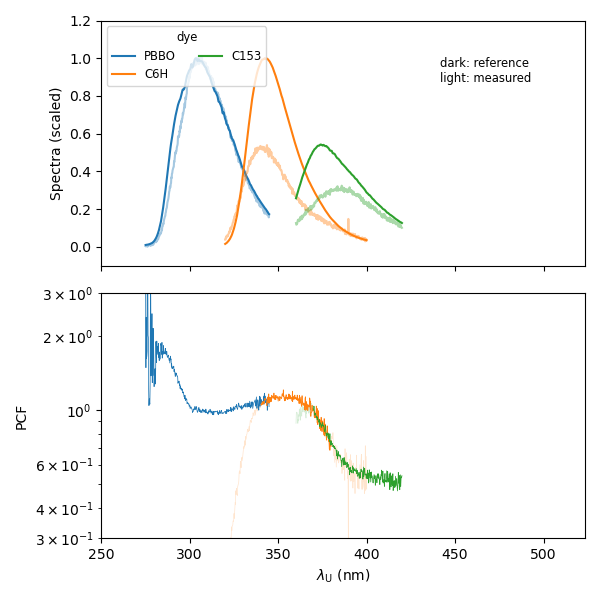

In [317]:
# scaling by average
fig, axes = plt.subplots(nrows=2, sharex=True, figsize=(6,6))

        
for k, r in references.items():
    m = meas[k]
    
    c = axes[0].plot(r.wl_u.compress(m.is_valid), r.s_u.compress(m.is_valid), label=k)
    axes[0].plot(m.wl_u.compress(m.is_valid), m.s_u.compress(m.is_valid), c=c[0].get_color(), alpha=0.4)
    
    wl_p, p = pcf_curves[k]
    axes[1].plot(wl_p, p*scales_rmsd[k], lw=0.5, color=c[0].get_color(), alpha=0.2, zorder=-1)
    m = pcf_is_valid[k]
    axes[1].plot(wl_p, np.where(m, p*scales_rmsd[k], np.nan), lw=0.5, color=c[0].get_color())
axes[0].legend(title="dye", fontsize='small', ncols=2, title_fontsize="small", loc="upper left")
axes[0].text(0.7, 0.85, "dark: reference\nlight: measured", ha="left", va="top", transform=axes[0].transAxes, fontsize="small")
axes[0].set_ylabel("Spectra (scaled)")
axes[0].set_ylim(-0.1, 1.2)
axes[1].set_yscale("log")
axes[1].set_ylim(0.3, 3)
axes[1].set_ylabel("PCF")
axes[1].set_xlabel(r"$\lambda_\mathrm{U}$ (nm)")
axes[1].set_xlim(wl_exp[0], wl_exp[-1])

plt.tight_layout()
#plt.savefig("260605_pcfs_scaled.png", dpi=300)
plt.show()

# COMMENTS:
# C6H maybe had reabsorption (seen on the blue side), so rather use the PBBO in that range
# better to measure dyes in cary FL spectro and use that as the reference!!

In [318]:
pcf_scaled = {k: (wl_, np.where(pcf_is_valid[k], p_*scales_rmsd[k], np.nan)) for k, (wl_, p_) in pcf_curves.items()}

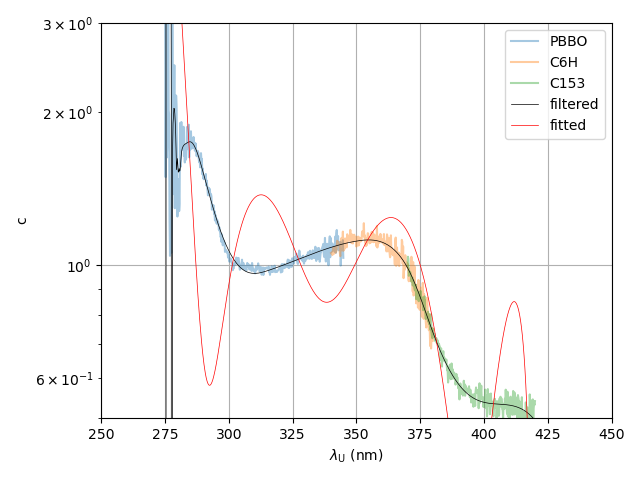

In [319]:
#prepare dataset for polynormial fitting.
pol_x = np.hstack([wl.compress(np.isfinite(p)) for wl, p in pcf_scaled.values()])
pol_y = np.hstack([p.compress(np.isfinite(p)) for wl, p in pcf_scaled.values()])
mask = between(pol_x, 265, 420) #pol_x > 306
polf = np.poly1d(np.polyfit(pol_x[mask], pol_y[mask], deg=7)) #deg=7
lo = np.min(pol_x)
hi = np.infty
wl_pol = wl_exp.compress(between(wl_exp, lo, hi))

srti = np.argsort(pol_x)
spln = UnivariateSpline(pol_x[srti], pol_y[srti], s=0.003*len(pol_x)) #hier dinge einstellen: 0.01
filtered = savgol_filter(spln(wl_pol), 21, 3) #40, 3
pcf = np.full_like(wl_exp, np.nan)
pcf[wl_exp > lo] = filtered

plt.figure()
for k, (wl, p) in pcf_scaled.items():
    plt.plot(wl, p, label=k, alpha=0.4)
plt.plot(wl_pol, filtered, color="k", lw=0.5, label="filtered")
plt.plot(wl_pol, polf(wl_pol), color='r', lw=0.5, label='fitted')
plt.yscale("log")
plt.ylim(0.5,3)
plt.xlim(250, 450)
plt.legend()
plt.xlabel(r"$\lambda_\mathrm{U}$ (nm)")
plt.ylabel("c")
plt.grid()
plt.tight_layout()
plt.show()

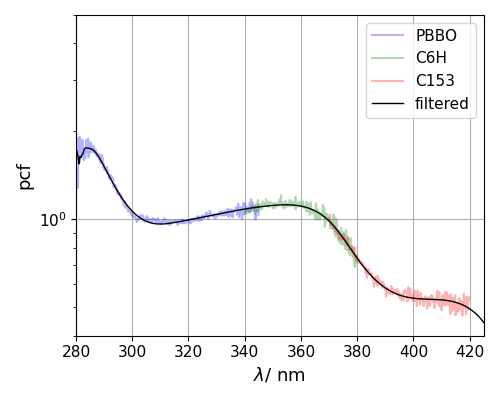

In [327]:
#
#prepare dataset for polynormial fitting.
pol_x = np.hstack([wl.compress(np.isfinite(p)) for wl, p in pcf_scaled.values()])
pol_y = np.hstack([p.compress(np.isfinite(p)) for wl, p in pcf_scaled.values()])
mask = pol_x > 255
polf = np.poly1d(np.polyfit(pol_x[mask], pol_y[mask], deg=7))
lo = np.min(pol_x)
hi = np.infty
wl_pol = wl_exp.compress(between(wl_exp, lo, hi))

srti = np.argsort(pol_x[mask])
spln = UnivariateSpline(pol_x[mask][srti], pol_y[mask][srti], s=0.003*len(pol_x[mask]))
filtered = savgol_filter(spln(wl_pol), 40, 3)
pcf = np.full_like(wl_exp, np.nan)
pcf[wl_exp > lo] = filtered

cut = wl_pol >= 255
filtered_cut = np.where(cut, filtered, np.nan)

colors=['b','g','r']

plt.figure(figsize=(5,4), dpi=100)
for (k, (wl, p)), c in zip(pcf_scaled.items(), colors):
    plt.plot(wl, p, c=c, label=k, alpha=0.3)
plt.plot(wl_pol, filtered_cut, color="k", lw=1, label="filtered")
plt.yscale("log")
plt.xlim(280, 425)
plt.ylim(0.4,5)
plt.legend(fontsize=11)
plt.xlabel(r"$\lambda$/ nm", fontsize=13)
plt.ylabel("pcf", fontsize=13)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid()
plt.tight_layout()
#plt.savefig('260605_FLUPS_pcf.png', dpi=500)
plt.show()

In [328]:
#np.savez("260605_pcf.npz", wl=wl_pol, pcf=filtered_cut)